# Immune-Cell Gene Regulatory Networks in Early Breast Cancer Dissemination

Author:     Oona Kintscher \
Created:    17.10.2026

### Global Variables

In [1]:
CELL_TYPE = "Activated T cells"

### Import Required Libraries

In [41]:
import sys
sys.path.append("..")

import os, re
import pandas as pd
import seaborn as sns
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist

from config.plotting import (
    MAIN_COLOR,
    ACCENT_COLOR,
    COLOR_PALETTE,
    COLOR_PALETTE_2,
    NAVY_WHITE
)

os.environ["CELL_TYPE"] = CELL_TYPE

from config.settings import (
    RESULTS_DIR,
    CELL_TYPE_DIR,
    GRN_INFERENCE_DIR
)

# Load Data

In [ ]:
L_metrics = pd.read_csv(
    RESULTS_DIR / "archive/grn-inference/Activated T cells/final/T/T - Regulon GRN Network default  node.csv"
)
display(L_metrics.head())

,AverageShortestPathLength,BetweennessCentrality,ClosenessCentrality,ClusteringCoefficient,Eccentricity,EdgeCount,in_degree,Indegree,is_target,is_TF,...,out_degree,Outdegree,pagerank,PartnerOfMultiEdgedNodePairs,selected,SelfLoops,shared name,Stress,weighted_in_degree,weighted_out_degree
0,5.124684,0.000000,0.195134,0.005142,10,58,0,0,False,True,...,58,58,0.000375,0,False,0,FOS,0,0.000000,38.111469
1,0.000000,0.000000,0.000000,0.000000,0,1,1,1,True,True,...,0,0,0.000419,0,False,0,JUNB,0,5.148122,0.000000
2,4.564872,2.009947,0.219064,0.004706,9,52,2,2,True,True,...,50,50,0.000396,1,False,0,JUN,13939938,2.452253,56.176838
3,6.420124,0.716266,0.155760,0.040476,11,23,6,6,True,True,...,17,17,0.000468,0,False,1,FOSB,5218332,9.323385,37.338038
4,1.055118,0.000000,0.947761,0.000000,2,122,1,1,True,True,...,121,121,0.000381,0,False,1,ETV7,0,1.000000,54.956996


In [7]:
T_metrics = pd.read_csv(
    RESULTS_DIR / "archive/grn-inference/Activated T cells/final/L/L - Regulon GRN Network default  node.csv"
)
display(T_metrics.head())

,AverageShortestPathLength,BetweennessCentrality,ClosenessCentrality,ClusteringCoefficient,Eccentricity,EdgeCount,in_degree,Indegree,is_target,is_TF,...,out_degree,Outdegree,pagerank,PartnerOfMultiEdgedNodePairs,selected,SelfLoops,shared name,Stress,weighted_in_degree,weighted_out_degree
0,3.477333,2.33165,0.287577,0.002269,9,261,1,1,True,True,...,260,260,0.000353,0,False,0,ELK1,19989761,1.220534,207.754550
1,0.000000,0.00000,0.000000,0.333333,0,4,4,4,True,False,...,0,0,0.000381,0,False,0,SMIM19,0,14.320574,0.000000
2,4.639214,0.00000,0.215554,0.003086,9,81,0,0,False,True,...,81,81,0.000347,0,False,0,ILF2,0,0.000000,54.893521
3,0.000000,0.00000,0.000000,0.000000,0,5,5,5,True,False,...,0,0,0.000388,0,False,0,UBE2J1,0,9.267671,0.000000
4,6.439812,0.02274,0.155284,0.000000,13,46,1,1,True,True,...,45,45,0.000387,1,False,0,FOS,177718,2.365184,84.781160


In [31]:
# Network Comparison - Metrics

In [11]:
L_tf_metrics = L_metrics.loc[L_metrics['is_TF'] == True]
T_tf_metrics = T_metrics.loc[T_metrics['is_TF'] == True]

plot_specs = ['AverageShortestPathLength', 'BetweennessCentrality',
       'ClosenessCentrality', 'ClusteringCoefficient', 'Eccentricity',
       'EdgeCount', 'Indegree', 'NeighborhoodConnectivity',
       'Outdegree','Stress']

for name, tf_metrics in [('T', T_tf_metrics), ('L', L_tf_metrics)]:
    no_regulator_tfs = tf_metrics[tf_metrics['Outdegree'] == 0]

    total_tfs = len(tf_metrics)
    unconnected_tfs = len(no_regulator_tfs)
    percentage = 100 * unconnected_tfs / total_tfs if total_tfs > 0 else 0

    print(f"\n{name} TF Statistics")
    print("-" * 30)
    print(f"Total TFs:          {total_tfs}")
    print(f"Unconnected TFs:    {unconnected_tfs}")
    print(f"Percentage unconnected: {percentage:.2f}%")


T TF Statistics
------------------------------
Total TFs:          377
Unconnected TFs:    269
Percentage unconnected: 71.35%

L TF Statistics
------------------------------
Total TFs:          355
Unconnected TFs:    237
Percentage unconnected: 66.76%


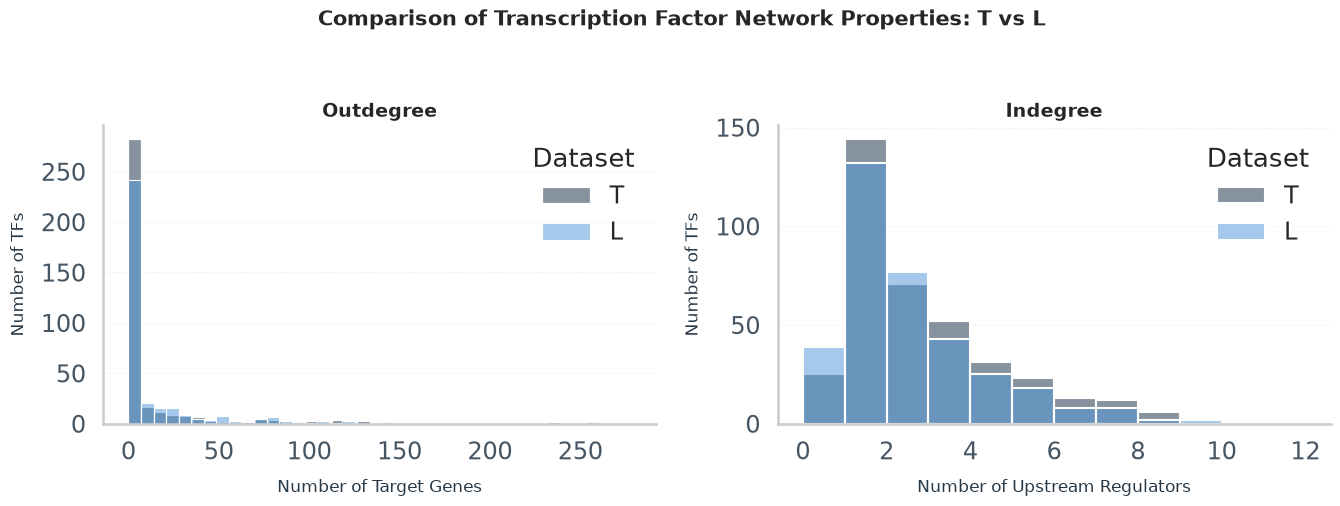

In [12]:
plot_specs = [
    ('Outdegree', 'Number of Target Genes'),
    ('Indegree', 'Number of Upstream Regulators'),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

datasets = [
    ('T', T_tf_metrics, MAIN_COLOR),
    ('L', L_tf_metrics, ACCENT_COLOR),
]

for ax, (col, xlabel) in zip(axes, plot_specs):
   
    combined_data = pd.concat(
        [df[col].dropna() for _, df, _ in datasets]
    )
    binwidth = max(1, (combined_data.max() - combined_data.min()) / 40)

    for name, df, color in datasets:
        sns.histplot(
            data=df[col].dropna(),
            binwidth=binwidth,
            color=color,
            alpha=0.5,
            edgecolor="white",
            label=name,
            ax=ax
        )

    ax.set_title(col, fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=12, labelpad=10)
    ax.set_ylabel("Number of TFs", fontsize=12, labelpad=10)
    ax.grid(axis="y", alpha=0.35)
    ax.grid(axis="x", visible=False)
    ax.legend(title="Dataset", frameon=False)
    sns.despine(ax=ax)

fig.suptitle(
    "Comparison of Transcription Factor Network Properties: T vs L",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

In [16]:
comparison = pd.DataFrame({
    "Network metric": [
        "Number of nodes",
        "Number of edges",
        "Average number of neighbors",
        "Network diameter",
        "Network radius",
        "Characteristic path length",
        "Clustering coefficient",
        "Network density",
        "Connected components",
        "Multi-edge node pairs",
        "Number of self-loops"
    ],
    "Regulon Tumor GRN Network": [
        2559, 5253, 4.066, 14, 1, 4.513,
        0.019, 0.001, 1, 8, 43
    ],
    "Regulon Lymph Node GRN Network": [
        2786, 6240, 4.439, 13, 1, 4.317,
        0.055, 0.001, 1, 14, 42
    ]
})

comparison["Change (%)"] = (
    (comparison["Regulon Lymph Node GRN Network"] - comparison["Regulon Tumor GRN Network"])
    / comparison["Regulon Tumor GRN Network"] * 100
).round(2)

print(comparison.to_string(index=False))

             Network metric  Regulon Tumor GRN Network  Regulon Lymph Node GRN Network  Change (%)
            Number of nodes                   2559.000                        2786.000        8.87
            Number of edges                   5253.000                        6240.000       18.79
Average number of neighbors                      4.066                           4.439        9.17
           Network diameter                     14.000                          13.000       -7.14
             Network radius                      1.000                           1.000        0.00
 Characteristic path length                      4.513                           4.317       -4.34
     Clustering coefficient                      0.019                           0.055      189.47
            Network density                      0.001                           0.001        0.00
       Connected components                      1.000                           1.000        0.00
      Mult

In [18]:
comparison.to_csv(CELL_TYPE_DIR / "network_comparison.csv", index=False)

In [19]:
network_comparison = pd.DataFrame({
    'Network Metric': [
        'Number of nodes',
        'Number of edges',
        'Average number of neighbors',
        'Network diameter',
        'Network radius',
        'Characteristic path length',
        'Clustering coefficient',
        'Network density',
        'Connected components',
        'Multi-edge node pairs',
        'Number of self-loops'
    ],
    'Lymph': [
        773, 2011, 5.144, 6, 1, 2.267,
        0.066, 0.003, 1, 5, 18
    ],
    'Tumor': [
        3974, 7460, 3.717, 12, 1, 4.231,
        0.016, 0.000, 1, 11, 64
    ]
})

network_comparison['Difference (Tumor - Lymph)'] = (
    network_comparison['Tumor'] - network_comparison['Lymph']
)

display(network_comparison)

,Network Metric,Lymph,Tumor,Difference (Tumor - Lymph)
0,Number of nodes,773.000,3974.000,3201.000
1,Number of edges,2011.000,7460.000,5449.000
2,Average number of neighbors,5.144,3.717,-1.427
3,Network diameter,6.000,12.000,6.000
4,Network radius,1.000,1.000,0.000
5,Characteristic path length,2.267,4.231,1.964
6,Clustering coefficient,0.066,0.016,-0.050
7,Network density,0.003,0.000,-0.003
8,Connected components,1.000,1.000,0.000
9,Multi-edge node pairs,5.000,11.000,6.000


# Enrichment Analysis

In [20]:
network_comparison.to_csv(
    CELL_TYPE_DIR / "lymph_tumor_network_comparison.csv",
    index=False
)

In [21]:
kegg = pd.read_csv(RESULTS_DIR / "archive/grn-inference/Activated T cells/final/enrichment-network-table-complete.csv")

In [22]:
kegg.columns

Index(['# background genes', '# genes', 'category', 'chart color',
       'description', 'FDR value', 'genes', 'network.SUID', 'nodes.SUID',
       'p-value', 'PMID', 'term name', 'transferred FDR value', 'year'],
      dtype='str')

In [23]:
go = pd.read_csv(RESULTS_DIR / "archive/grn-inference/Activated T cells/final/enrichment-network-table-complete-GO.csv")

In [24]:
go.columns

Index(['# background genes', '# genes', 'category', 'chart color',
       'description', 'FDR value', 'genes', 'network.SUID', 'nodes.SUID',
       'p-value', 'PMID', 'term name', 'transferred FDR value', 'year'],
      dtype='str')

In [25]:
kegg.columns = kegg.columns.str.strip()
go.columns = go.columns.str.strip()


def prepare(df):
    df = df.copy()
    df["FDR value"] = pd.to_numeric(df["FDR value"], errors="coerce")
    df["# genes"] = pd.to_numeric(df["# genes"], errors="coerce")

    df = df.dropna(subset=["description", "FDR value", "# genes"])
    df = df[
        (df["FDR value"] > 0) &
        (df["FDR value"] <= 0.05)
    ].copy()

    df["term_key"] = (
        df["description"].astype(str).str.strip().str.lower()
    )
    return df


kegg = prepare(kegg)
go = prepare(go)

top_kegg = kegg.nsmallest(5, "FDR value").copy()
top_go = go.nsmallest(5, "FDR value").copy()

shared = kegg.merge(
    go,
    on="term_key",
    suffixes=("_KEGG", "_GO"),
    how="inner"
)

shared["combined_score"] = (
    -np.log10(shared["FDR value_KEGG"])
    -np.log10(shared["FDR value_GO"])
) / 2

shared = (
    shared.sort_values("combined_score", ascending=False)
    .drop_duplicates("term_key")
)
top_shared = shared.head(5).copy()

kegg_plot = pd.DataFrame({
    "Term": top_kegg["description"],
    "Significance": -np.log10(top_kegg["FDR value"]),
    "Gene count": top_kegg["# genes"],
    "Source": "KEGG"
})

go_plot = pd.DataFrame({
    "Term": top_go["description"],
    "Significance": -np.log10(top_go["FDR value"]),
    "Gene count": top_go["# genes"],
    "Source": "GO Biological Process"
})

shared_plot = pd.DataFrame({
    "Term": top_shared["description_KEGG"],
    "Significance": top_shared["combined_score"],
    "Gene count": top_shared[["# genes_KEGG", "# genes_GO"]].max(axis=1),
    "Source": "Shared KEGG + GO"
})

plot_df = pd.concat(
    [kegg_plot, go_plot, shared_plot],
    ignore_index=True
)

plot_df["Term"] = plot_df["Term"].astype(str)

plot_df["Label"] = plot_df["Term"]

plot_df = plot_df.sort_values("Significance", ascending=True)

In [26]:
top_shared

,# background genes_KEGG,# genes_KEGG,category_KEGG,chart color_KEGG,description_KEGG,FDR value_KEGG,genes_KEGG,network.SUID_KEGG,nodes.SUID_KEGG,p-value_KEGG,...,FDR value_GO,genes_GO,network.SUID_GO,nodes.SUID_GO,p-value_GO,PMID_GO,term name_GO,transferred FDR value_GO,year_GO,combined_score
1,285,51,Reactome Pathways,NaN,Epigenetic regulation of gene expression,0.000018,BOD1L1|CBX5|MED17|TRIM28|ZNF331|H3-3B|MBD2|KMT...,431980,435141|432774|436266|434244|432927|433200|4355...,5.480000e-07,...,6.650000e-11,HDAC7|CBX5|EGR1|RIF1|TRIM28|H3-3B|MBD2|EPC1|EP...,431980,436701|432774|433977|433002|434244|433200|4355...,6.050000e-13,NaN,GO:0040029,1.017718,0,7.457364
4,30,9,WikiPathways,NaN,Autophagy,0.005900,RB1CC1|PIK3C3|PRKAG2|ULK1|UVRAG|BECN1|ATG5|ATG...,431980,433806|432843|436959|435837|436290|435366|4334...,7.400000e-04,...,3.800000e-08,RB1CC1|XBP1|CHMP5|VPS4B|STX17|PIK3C3|RAB2A|CHM...,431980,433806|434685|435567|437022|435264|432843|4349...,4.790000e-10,NaN,GO:0006914,0.742022,0,4.824682
2,194,38,Reactome Pathways,NaN,Cellular response to chemical stress,0.000045,CSNK2A1|NFKB1|COX5B|TGS1|PSMA6|CSNK2A2|EP300|C...,431980,435942|434901|436572|433638|434544|436059|4342...,1.600000e-06,...,8.740000e-06,SETX|PYROXD1|CAB39|RIPK1|KAT2B|PIK3CA|ATF2|TOP...,431980,432267|433176|436539|436815|432318|434973|4342...,1.600000e-07,NaN,GO:0062197,0.505849,0,4.702638
0,249,49,KEGG Pathways,NaN,Endocytosis,0.000001,SPG21|WASL|CHMP5|VPS4B|RAB22A|RAB11A|SMAD2|ARF...,431980,432375|434763|435567|437022|434013|433452|4366...,4.520000e-08,...,5.300000e-03,RALA|MTMR9|RAB22A|CANX|RABGAP1L|RARA|ITGAV|CLC...,431980,435987|432123|434013|434721|434949|436545|4346...,2.300000e-04,NaN,GO:0006897,0.227572,0,4.084257
3,106,22,KEGG Pathways,NaN,Nucleocytoplasmic transport,0.000630,THOC2|NXT1|KPNA3|ACIN1|NUP54|TNPO3|THOC7|NUP98...,431980,434079|437088|436254|433497|435666|433836|4362...,9.820000e-05,...,1.600000e-05,NUTF2|PPP3R1|ATXN1|THOC2|NXT1|BACH2|AKIRIN2|CT...,431980,432462|432432|436755|434079|437088|435480|4337...,3.080000e-07,NaN,GO:0006913,0.479588,0,3.998270


In [27]:
top_kegg

,# background genes,# genes,category,chart color,description,FDR value,genes,network.SUID,nodes.SUID,p-value,PMID,term name,transferred FDR value,year,term_key
0,2551,365,Reactome Pathways,NaN,Signal Transduction,1.060000e-20,FKBP4|RALA|RANBP9|FAM13B|HDAC7|PPP1R15A|GMIP|G...,431980,433926|435987|433272|434016|436701|433905|4335...,4.260000e-24,NaN,HSA-162582,1.997469,0,signal transduction
1,1539,246,Reactome Pathways,NaN,Gene expression (Transcription),3.760000e-19,BOD1L1|HDAC7|CDK13|PPP1R13B|CBX5|PAPOLA|SNAPC1...,431980,435141|436701|433611|434712|432774|437184|4366...,3.040000e-22,NaN,HSA-74160,1.842481,0,gene expression (transcription)
2,2105,308,Reactome Pathways,NaN,Immune System,1.050000e-18,FUCA2|RALA|CDK13|SOS2|CSNK2A1|CSK|PAG1|WASL|NF...,431980,436383|435987|433611|435831|435942|435609|4343...,1.270000e-21,NaN,HSA-168256,1.797881,0,immune system
3,998,172,Reactome Pathways,NaN,Infectious disease,2.800000e-16,FKBP4|SUPT16H|CSNK2A1|WASL|CHMP5|NFKB1|NR3C1|V...,431980,433926|436647|435942|434763|435567|434901|4358...,6.770000e-19,NaN,HSA-5663205,1.555284,0,infectious disease
4,671,129,Reactome Pathways,NaN,Signaling by Rho GTPases,8.200000e-16,FAM13B|GMIP|GOLGA3|SOS2|TXNL1|CSK|WASL|PFN1|ST...,431980,434016|433515|435249|435831|436296|435609|4347...,3.020000e-18,NaN,HSA-194315,1.508619,0,signaling by rho gtpases


In [28]:
top_go

,# background genes,# genes,category,chart color,description,FDR value,genes,network.SUID,nodes.SUID,p-value,PMID,term name,transferred FDR value,year,term_key
0,6170,869,GO Biological Process,NaN,Regulation of metabolic process,1.270000e-64,CYP51A1|RANBP9|RB1CC1|HDAC7|CDK13|RBM22|PPP1R1...,431980,432705|433272|433806|436701|433611|432924|4339...,1.030000e-68,NaN,GO:0019222,6.389620,0,regulation of metabolic process
1,1788,343,GO Biological Process,NaN,Positive regulation of RNA metabolic process,4.560000e-46,CDK13|XBP1|GTPBP1|ZBED4|SUPT16H|MAZ|MGA|GABPB1...,431980,433611|434685|434067|437148|436647|437175|4335...,5.560000e-49,NaN,GO:0051254,4.534104,0,positive regulation of rna metabolic process
2,5355,732,GO Biological Process,NaN,Macromolecule metabolic process,4.310000e-45,FKBP4|UBR7|RB1CC1|BOD1L1|HDAC7|APPBP2|CDK13|RB...,431980,433926|433620|433806|435141|436701|437061|4336...,5.600000e-48,NaN,GO:0043170,4.436552,0,macromolecule metabolic process
3,2522,421,GO Biological Process,NaN,Negative regulation of macromolecule metabolic...,1.160000e-41,CYP51A1|HDAC7|CBX5|XBP1|CSNK2A1|MAZ|CSK|EIF3E|...,431980,432705|436701|432774|434685|435942|437175|4356...,1.790000e-44,NaN,GO:0010605,4.093554,0,negative regulation of macromolecule metabolic...
4,824,202,GO Biological Process,NaN,Chromatin organization,2.550000e-41,HDAC7|CBX5|SUPT16H|JADE1|ASF1A|STK38|NR3C1|MSH...,431980,436701|432774|436647|432288|436671|432249|4358...,4.140000e-44,NaN,GO:0006325,4.059346,0,chromatin organization


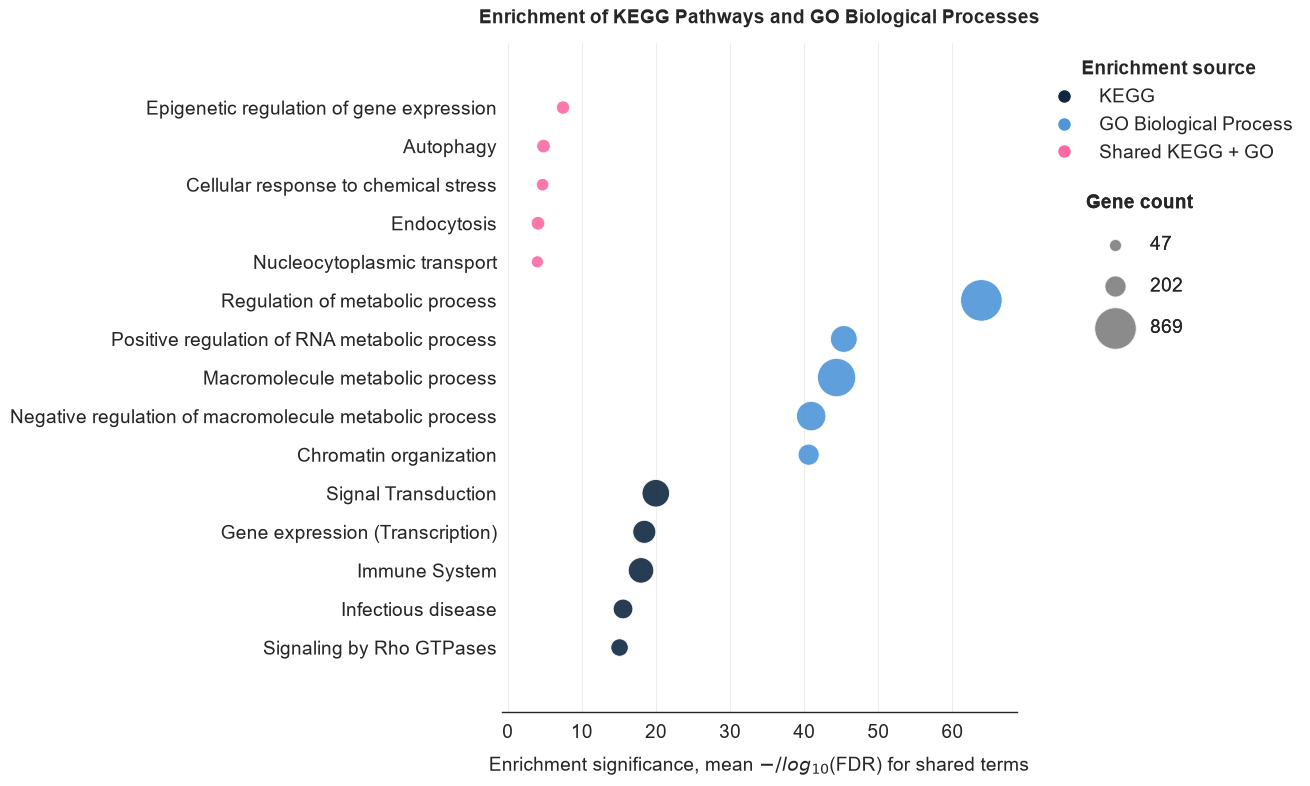

In [ ]:
sns.set_theme(style="white", context="paper", font_scale=1.15)

palette = {
    "KEGG": MAIN_COLOR,
    "GO Biological Process": ACCENT_COLOR,
    "Shared KEGG + GO": "#FA69A3" 
}

fig_height = max(8, len(plot_df) * 0.5)
fig, ax = plt.subplots(figsize=(13, fig_height))

size_scale = 30

for source in ["KEGG", "GO Biological Process", "Shared KEGG + GO"]:
    subset = plot_df[plot_df["Source"] == source]

    if subset.empty:
        continue

    ax.scatter(
        subset["Significance"],
        subset["Label"],
        s=size_scale + subset["Gene count"],
        color=palette[source],
        label=source,
        alpha=0.9,
        edgecolor="white",
        linewidth=0.7,
        zorder=3
    )

ax.set_xlabel(
    r"Enrichment significance, mean $-/log_{10}$(FDR) for shared terms",
    fontsize=14,
    labelpad=10
)
ax.set_ylabel("")
ax.set_title(
    "Enrichment of KEGG Pathways and GO Biological Processes",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.margins(y=0.12, x=0.08)
ax.grid(axis="x", alpha=0.35)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0, labelsize=14)
ax.tick_params(axis="x", labelsize=14)

source_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="white",
        markersize=10,
        label=source
    )
    for source, color in palette.items()
    if source in plot_df["Source"].unique()
]

source_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="white",
        markersize=10,
        label=source
    )
    for source, color in palette.items()
    if source in plot_df["Source"].unique()
]

legend1 = ax.legend(
    handles=source_handles,
    title="Enrichment source",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    frameon=False,
    fontsize=14,
    title_fontproperties={"size": 14, "weight": "bold"},
)
ax.add_artist(legend1)

gene_counts = plot_df["Gene count"].dropna()
size_values = sorted(set([
    int(gene_counts.min()),
    int(gene_counts.median()),
    int(gene_counts.max())
]))

size_handles = [
    ax.scatter(
        [], [],
        s=size_scale + count,
        color="grey",
        alpha=0.7,
        edgecolor="white",
        label=str(count)
    )
    for count in size_values
]

legend2 = ax.legend(
    handles=size_handles,
    title="Gene count",
    loc="upper left",
    bbox_to_anchor=(1.1, 0.8),
    frameon=False,
    fontsize=14,
    title_fontproperties={"size": 14, "weight": "bold"},
    labelspacing=1.2
)
ax.add_artist(legend2)

fig.tight_layout(rect=[0, 0, 0.80, 1])

# AUCell Analysis

In [33]:
edge_file = RESULTS_DIR / "archive/grn-inference/Activated T cells/final/Overlap - Regulon GRN Network default  edge.csv"
lymph_file = RESULTS_DIR / "archive/grn-inference/Activated T cells/final/L/pyscenic_aucell.csv"
tumor_file = RESULTS_DIR / "archive/grn-inference/Activated T cells/final/T/pyscenic_aucell.csv"

In [34]:
edges = pd.read_csv(edge_file)

edges.columns = edges.columns.str.strip()

if "regulon" not in edges.columns:
    raise ValueError(
        "The overlap edge table does not contain a 'regulon' column."
    )

overlap_regulons = (
    edges["regulon"]
    .dropna()
    .astype(str)
    .str.strip()
)

overlap_regulons = sorted(
    set(overlap_regulons[overlap_regulons != ""])
)

print(f"Unique overlap regulons: {len(overlap_regulons)}")

Unique overlap regulons: 44


In [35]:
def base_tf(name):
    return re.sub(r"\s*\([+-]\)\s*$", "", str(name)).strip()

overlap_tfs = set(base_tf(r) for r in overlap_regulons)

# Load AUCell tables: rows = regulons, columns = cells
tumor = pd.read_csv(tumor_file, index_col=0)
lymph = pd.read_csv(lymph_file, index_col=0)

tumor.index = tumor.index.astype(str).str.strip()
lymph.index = lymph.index.astype(str).str.strip()

tumor = tumor.apply(pd.to_numeric, errors="coerce")
lymph = lymph.apply(pd.to_numeric, errors="coerce")

In [36]:
def match_regulons(edge_regulons, aucell_columns):
    matched = []

    for name in edge_regulons:
        name = name.strip()

        if re.search(r"\([+-]\)$", name):
            # Direction is specified: exact match only
            if name in aucell_columns:
                matched.append(name)
        else:
            # Base TF name: include available positive/negative variants
            variants = [
                col for col in aucell_columns
                if re.fullmatch(
                    re.escape(name) + r"\s*\([+-]\)",
                    col
                )
            ]
            matched.extend(variants)

    return sorted(set(matched))

In [37]:
tumor_regulons = match_regulons(
    overlap_regulons, tumor.columns
)
lymph_regulons = match_regulons(
    overlap_regulons, lymph.columns
)

# Use the same regulons in both conditions
common_regulons = sorted(
    set(tumor_regulons) & set(lymph_regulons)
)

if not common_regulons:
    raise ValueError(
        "No matching regulons found. Check the names in "
        "the edge table and AUCell column headers."
    )

print("Matched tumor regulons:", len(tumor_regulons))
print("Matched lymph node regulons:", len(lymph_regulons))
print("Common regulons plotted:", len(common_regulons))

Matched tumor regulons: 44
Matched lymph node regulons: 44
Common regulons plotted: 44


In [39]:
tumor_heatmap = tumor[common_regulons].apply(
    pd.to_numeric, errors="coerce"
).T

lymph_heatmap = lymph[common_regulons].apply(
    pd.to_numeric, errors="coerce"
).T

all_values = np.concatenate([
    tumor_heatmap.to_numpy().ravel(),
    lymph_heatmap.to_numpy().ravel()
])
all_values = all_values[np.isfinite(all_values)]

vmin = all_values.min()
vmax = all_values.max()

Text(0.5, 0.96, 'AUCell Activity of Shared GRN Regulons')

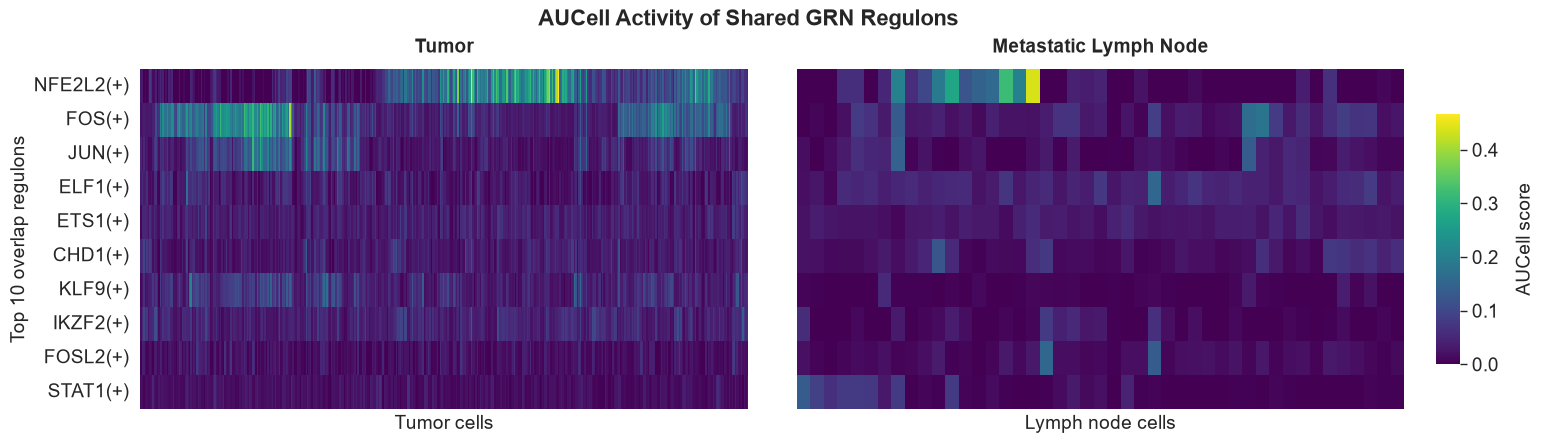

In [42]:
mean_activity = (
    tumor_heatmap.mean(axis=1) +
    lymph_heatmap.mean(axis=1)
) / 2

top10_regulons = mean_activity.nlargest(10).index.tolist()

tumor_top10 = tumor_heatmap.loc[top10_regulons].fillna(0)
lymph_top10 = lymph_heatmap.loc[top10_regulons].fillna(0)

def order_cells(matrix):
    # Input: rows = regulons, columns = cells
    cell_matrix = matrix.T

    # Remove constant regulons for correlation distance
    cell_matrix = cell_matrix.loc[
        :, cell_matrix.nunique(axis=0) > 1
    ]

    if cell_matrix.shape[1] < 2 or cell_matrix.shape[0] < 2:
        return matrix

    distances = pdist(cell_matrix, metric="correlation")
    distances = np.nan_to_num(distances, nan=1.0)

    Z = linkage(distances, method="average")
    order = leaves_list(Z)

    return matrix.iloc[:, order]


tumor_ordered = order_cells(tumor_top10)
lymph_ordered = order_cells(lymph_top10)

all_values = np.concatenate([
    tumor_ordered.to_numpy().ravel(),
    lymph_ordered.to_numpy().ravel()
])

vmin = np.nanmin(all_values)
vmax = np.nanmax(all_values)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    gridspec_kw={"width_ratios": [1, 1]}
)

fig.subplots_adjust(
    left=0.12,
    right=0.91,
    bottom=0.16,
    top=0.84,
    wspace=0.08
)

cbar_ax = fig.add_axes([0.93, 0.25, 0.015, 0.5])

sns.heatmap(
    tumor_ordered,
    ax=axes[0],
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    xticklabels=False,
    yticklabels=True,
    cbar=True,
    cbar_ax=cbar_ax
)

sns.heatmap(
    lymph_ordered,
    ax=axes[1],
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    xticklabels=False,
    yticklabels=False,
    cbar=False
)

axes[0].set_title(
    "Tumor",
    fontsize=14,
    fontweight="bold",
    pad=12
)
axes[1].set_title(
    "Metastatic Lymph Node",
    fontsize=14,
    fontweight="bold",
    pad=12
)

axes[0].set_xlabel("Tumor cells", fontsize=14)
axes[1].set_xlabel("Lymph node cells", fontsize=14)
axes[0].set_ylabel("Top 10 overlap regulons", fontsize=14)
axes[1].set_ylabel("")

axes[0].tick_params(axis="y", labelsize=14, rotation=0)

cbar_ax.set_ylabel("AUCell score", rotation=90, labelpad=12, fontsize=14)
cbar_ax.tick_params(labelsize=14)

fig.suptitle(
    "AUCell Activity of Shared GRN Regulons",
    fontsize=16,
    fontweight="bold",
    y=0.96
)